# 01 - EEG Exploratory Data Analysis (EDA)
Checks class balance, file/trial consistency, data quality (NaNs, flat channels, outliers) and looks for Event-Related Desynchronization (ERD) in the mu/beta bands on C3 and C4.

**Before running:** put the Excel files in `data/eeg_files/` (or change `DATA_DIR` in Cell 1) and set the real sampling rate `FS`. Run the cells from top to bottom.

### Cell 1 - Configuration
Imports the libraries and sets the main constants: the Excel folder `DATA_DIR`, the sampling rate `FS`, the band limits and the quality thresholds. It also defines the helper functions (natural file sorting, Excel loader, filename-label mapping) used by all later cells.

In [1]:
import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import signal
from scipy.integrate import trapezoid
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

# ---------------- Paths / constants (EDIT HERE) ----------------
DATA_DIR   = "data/eeg_files"   # folder with the Excel trial files (sub-folders are searched too)
LABELS_CSV = "labels.csv"       # CSV with a 'label' column (Left / Right), same order as the sorted files
FS         = 256                # sampling rate in Hz  <-- set the real value of your recording
HEADER     = 0                  # Excel header row (None if files have no header)
NOTCH_HZ   = 50                 # power-line frequency
SEED       = 42

NON_EEG_HINTS = ("TIME", "LABEL", "UNNAMED", "INDEX")   # columns that are not EEG channels

# ---------------- Helper functions ----------------
def natural_key(path):
    """Sort key: trial_2.xlsx comes before trial_10.xlsx."""
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", os.path.basename(path))]

def list_trial_files(data_dir):
    files = glob.glob(os.path.join(data_dir, "**", "*.xls*"), recursive=True)
    files = [f for f in files if not os.path.basename(f).startswith("~$")]
    return sorted(files, key=natural_key)

def read_trial(path):
    """One Excel file -> numeric DataFrame (rows = samples, columns = EEG channels, UPPER-CASE names)."""
    df = pd.read_excel(path, header=HEADER)
    df.columns = [str(c).strip().upper() for c in df.columns]
    df = df.drop(columns=[c for c in df.columns if any(h in c for h in NON_EEG_HINTS)])
    return df.apply(pd.to_numeric, errors="coerce")

def build_mapping():
    """Clean filename <-> label mapping (uses a 'filename' column if present, else the sorted file order)."""
    labels = pd.read_csv(LABELS_CSV)
    labels["label"] = labels["label"].astype(str).str.strip().str.capitalize()
    if "filename" in labels.columns:
        m = labels.copy()
        m["path"] = m["filename"].apply(lambda f: os.path.join(DATA_DIR, f))
    else:
        files = list_trial_files(DATA_DIR)
        assert len(files) == len(labels), (
            f"{len(files)} Excel files in '{DATA_DIR}' but {len(labels)} labels in '{LABELS_CSV}'. "
            "Check DATA_DIR or add a 'filename' column to the CSV.")
        m = pd.DataFrame({"filename": [os.path.basename(f) for f in files], "path": files, "label": labels["label"].values})
    m.insert(0, "trial_id", range(len(m)))
    return m

# ---------------- EDA-specific settings ----------------
MU, BETA = (8, 12), (13, 30)    # frequency bands for ERD
FLAT_STD = 1e-6                 # std below this = flat channel
Z_THR, OUTLIER_FRAC_THR = 6.0, 0.01   # robust z-score limit and max allowed fraction of outlier samples
MAX_Z_THR = 50.0                      # a single sample above this robust z-score = extreme spike
print("Config OK | FS =", FS, "| DATA_DIR =", DATA_DIR)

Config OK | FS = 256 | DATA_DIR = data/eeg_files


### Cell 2 - Clean Mapping
Matches the Excel files (in natural sorted order) with the rows of `labels.csv` and saves the clean filename-to-label table as `trial_label_mapping.csv`. It also checks that every file exists.

In [2]:
mapping = build_mapping()
mapping[["trial_id", "filename", "label"]].to_csv("trial_label_mapping.csv", index=False)
print("Trials:", len(mapping), "| missing files:", int((~mapping["path"].apply(os.path.exists)).sum()))
mapping.head()

Trials: 2400 | missing files: 0


,trial_id,filename,path,label
0,0,trial_1.xlsx,data/eeg_files\trial_1.xlsx,Left
1,1,trial_2.xlsx,data/eeg_files\trial_2.xlsx,Right
2,2,trial_3.xlsx,data/eeg_files\trial_3.xlsx,Left
3,3,trial_4.xlsx,data/eeg_files\trial_4.xlsx,Left
4,4,trial_5.xlsx,data/eeg_files\trial_5.xlsx,Left


### Cell 3 - Class Balance
Counts how many `Left` and `Right` trials exist, prints the percentage and the majority/minority ratio, and draws a bar chart.

       count  percent
label                
Right   1213    50.54
Left    1187    49.46
Majority/minority ratio = 1.022 (close to 1.0 = balanced)


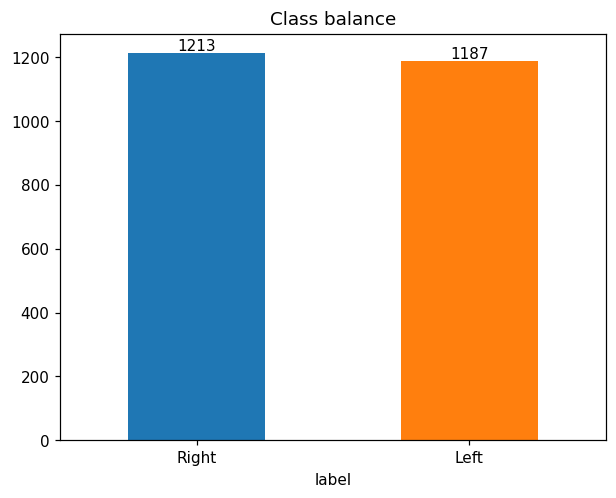

In [3]:
counts = mapping["label"].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)}))
print(f"Majority/minority ratio = {counts.max() / counts.min():.3f} (close to 1.0 = balanced)")
ax = counts.plot(kind="bar", color=["tab:blue", "tab:orange"], rot=0, title="Class balance")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

### Cell 4 - Single Trial Inspection
Opens one trial to see its shape `(samples x channels)`, the channel names, its duration, the basic statistics per channel, and (if the file has a time column) the real sampling rate.

In [4]:
raw_head = pd.read_excel(mapping["path"].iloc[0], header=HEADER)
trial0 = read_trial(mapping["path"].iloc[0])
print("Shape (samples x channels):", trial0.shape, "| duration:", round(len(trial0) / FS, 2), "s at FS =", FS)
print("Channels:", list(trial0.columns))
time_cols = [c for c in raw_head.columns if "time" in str(c).lower()]
if time_cols:
    print("Sampling rate estimated from time column:", round(1 / np.median(np.diff(raw_head[time_cols[0]].astype(float))), 1), "Hz")
trial0.describe().T.round(3)

Shape (samples x channels): (1024, 8) | duration: 4.0 s at FS = 256
Channels: ['C3', 'C4', 'F3', 'F4', 'P3', 'P4', 'O1', 'O2']


,count,mean,std,min,25%,50%,75%,max
C3,1024.0,-0.293,12.533,-44.274,-8.663,-0.708,8.362,38.950
C4,1024.0,-0.735,10.379,-32.226,-7.683,-0.526,6.378,32.034
F3,1024.0,0.338,12.755,-37.855,-8.400,-0.184,8.537,41.392
F4,1024.0,-0.031,11.640,-34.271,-8.180,-0.296,7.799,40.644
P3,1024.0,-0.286,11.879,-38.280,-8.238,-0.066,8.277,43.343
P4,1024.0,0.509,12.894,-40.122,-8.678,0.604,8.986,40.863
O1,1024.0,0.398,13.632,-40.371,-9.101,-0.234,9.741,47.359
O2,1024.0,-0.481,12.090,-38.504,-8.327,-0.519,7.775,49.884


### Cell 5 - Dataset-Wide Quality Audit
Loops over ALL files (in parallel) and records for each trial: length, channel layout, NaN count, flat channels, and outliers (robust z-score based on the median and MAD; many outlier samples or one extreme spike). In the same pass it computes the Welch PSD of C3 and C4, so the files are read only once.

In [5]:
def audit_trial(path):
    df = read_trial(path)
    x = df.values.astype("float64")
    n, c = x.shape
    out = {"n_samples": n, "n_channels": c, "layout": tuple(df.columns), "n_nan": int(np.isnan(x).sum())}
    std = np.nanstd(x, axis=0)
    out["n_flat"] = int((np.isnan(std) | (std < FLAT_STD)).sum())
    med = np.nanmedian(x, axis=0)
    mad = np.nanmedian(np.abs(x - med), axis=0)
    mad = np.where(mad < 1e-12, np.nan, mad)
    rz = 0.6745 * (x - med) / mad                                  # robust z-score per channel
    out["outlier_frac"] = float((np.abs(rz) > Z_THR).mean())
    out["max_rz"] = float(np.nanmax(np.abs(rz))) if np.isfinite(rz).any() else 0.0
    out["max_abs"] = float(np.nanmax(np.abs(x - med)))
    out["psd_c3"] = out["psd_c4"] = None
    if {"C3", "C4"} <= set(df.columns) and out["n_nan"] == 0 and n >= FS:
        _, p = signal.welch(x[:, [df.columns.get_loc("C3"), df.columns.get_loc("C4")]], fs=FS,
                            nperseg=FS, noverlap=FS // 2, detrend="constant", axis=0)
        out["psd_c3"], out["psd_c4"] = p[:, 0], p[:, 1]
    return out

results = Parallel(n_jobs=-1, verbose=5)(delayed(audit_trial)(p) for p in mapping["path"])
audit = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("psd")} for r in results])
audit = pd.concat([mapping[["trial_id", "filename", "label"]], audit], axis=1)
freqs = np.fft.rfftfreq(FS, 1 / FS)                                # frequency grid of the PSD (1 Hz resolution)
print("Audit finished for", len(audit), "trials")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    8.5s
[Parallel(n_jobs=-1)]: Done  56 tasks      | elapsed:   10.5s
[Parallel(n_jobs=-1)]: Done 146 tasks      | elapsed:   13.3s
[Parallel(n_jobs=-1)]: Done 272 tasks      | elapsed:   17.0s
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:   22.1s
[Parallel(n_jobs=-1)]: Done 632 tasks      | elapsed:   28.5s
[Parallel(n_jobs=-1)]: Done 866 tasks      | elapsed:   36.9s
[Parallel(n_jobs=-1)]: Done 1136 tasks      | elapsed:   46.3s
[Parallel(n_jobs=-1)]: Done 1442 tasks      | elapsed:   56.5s
[Parallel(n_jobs=-1)]: Done 1784 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 2162 tasks      | elapsed:  1.4min


Audit finished for 2400 trials


[Parallel(n_jobs=-1)]: Done 2400 out of 2400 | elapsed:  1.6min finished


### Cell 6 - Quality Summary & Plots
Flags every problem (different channel layout, NaNs, flat channels, outliers), prints a summary table, defines the final `is_bad` mask, and plots the trial-duration distribution and the maximum amplitude per trial.

different channel layout        0
trials with NaNs                0
trials with flat channels       0
trials with outliers            0
bad trials (any problem)        0
total                        2400
count    2400.0
mean        4.0
std         0.0
min         4.0
25%         4.0
50%         4.0
75%         4.0
max         4.0


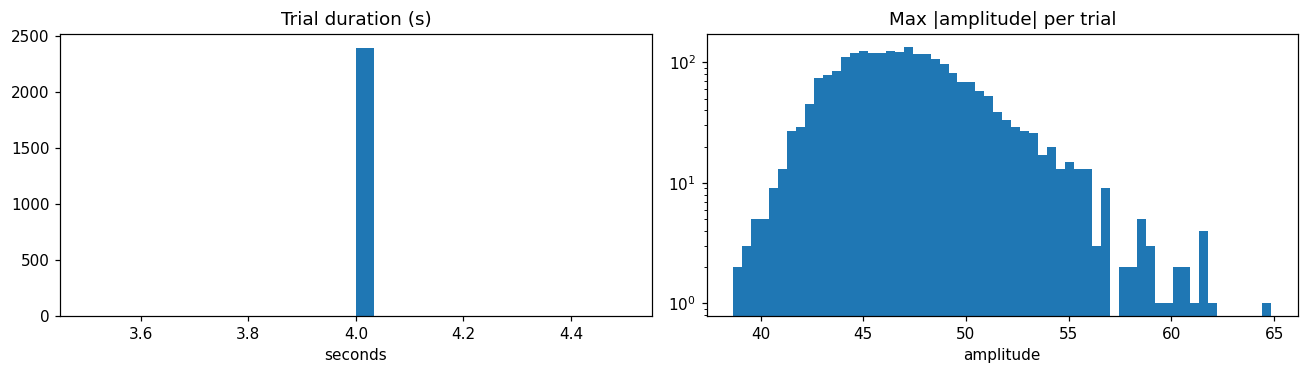

In [6]:
common_layout = audit["layout"].mode()[0]
audit["layout_ok"] = audit["layout"].apply(lambda l: l == common_layout)
audit["duration_s"] = audit["n_samples"] / FS
audit["has_nan"], audit["has_flat"] = audit["n_nan"] > 0, audit["n_flat"] > 0
audit["has_outliers"] = (audit["outlier_frac"] > OUTLIER_FRAC_THR) | (audit["max_rz"] > MAX_Z_THR)
audit["is_bad"] = (~audit["layout_ok"]) | audit["has_nan"] | audit["has_flat"] | audit["has_outliers"]
print(pd.Series({"different channel layout": int((~audit.layout_ok).sum()), "trials with NaNs": int(audit.has_nan.sum()),
                 "trials with flat channels": int(audit.has_flat.sum()), "trials with outliers": int(audit.has_outliers.sum()),
                 "bad trials (any problem)": int(audit.is_bad.sum()), "total": len(audit)}).to_string())
print(audit["duration_s"].describe().round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(audit["duration_s"], bins=30); ax[0].set_title("Trial duration (s)"); ax[0].set_xlabel("seconds")
ax[1].hist(audit["max_abs"], bins=60); ax[1].set_yscale("log"); ax[1].set_title("Max |amplitude| per trial"); ax[1].set_xlabel("amplitude")
plt.tight_layout(); plt.show()

### Cell 7 - Time-Domain Plots
Plots C3 and C4 for 2 random good `Left` trials and 2 random good `Right` trials: the raw signal (grey, demeaned) against the signal band-pass filtered in the motor band 8-30 Hz (blue).

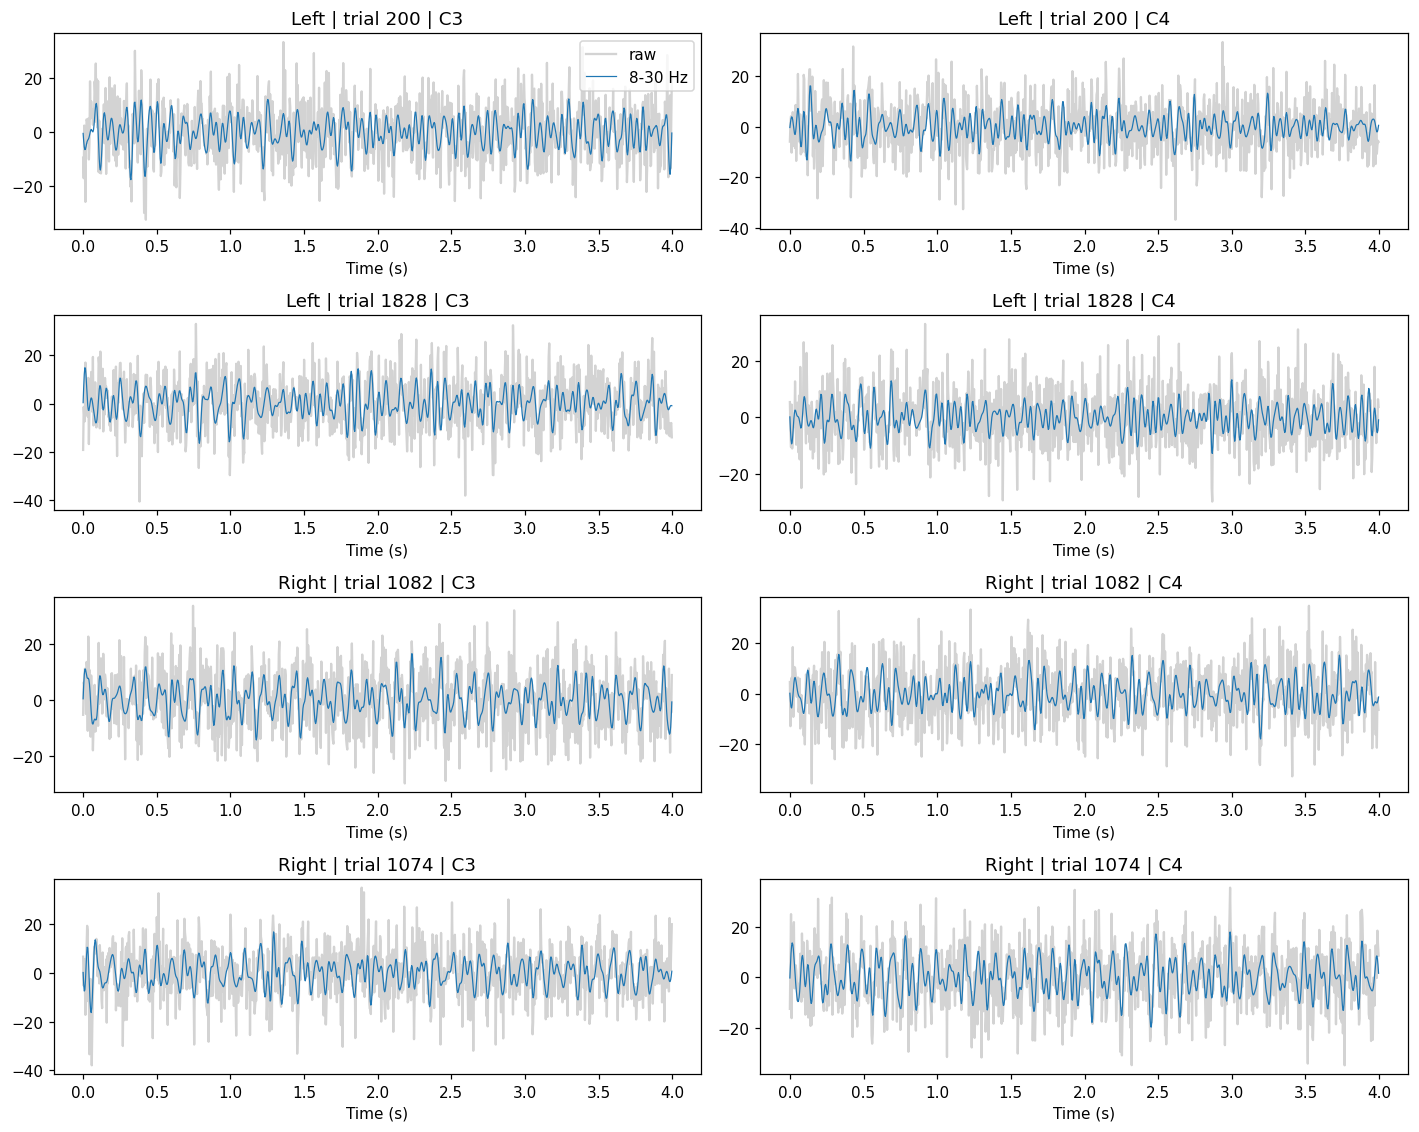

In [7]:
channels = list(common_layout)
assert "C3" in channels and "C4" in channels, f"C3/C4 not found in {channels}"
sos = signal.butter(4, [8, 30], btype="band", fs=FS, output="sos")
rng = np.random.default_rng(SEED)
good = audit[~audit["is_bad"]]
picks = [(cls, int(i)) for cls in ["Left", "Right"]
         for i in rng.choice(good.index[good["label"] == cls], 2, replace=False)]

fig, axes = plt.subplots(len(picks), 2, figsize=(13, 2.6 * len(picks)))
for row, (cls, i) in enumerate(picks):
    x = read_trial(mapping["path"][i])[channels].values.astype(float)
    xf = signal.sosfiltfilt(sos, x - x.mean(axis=0), axis=0)
    t = np.arange(len(x)) / FS
    for ax, name in zip(axes[row], ["C3", "C4"]):
        k = channels.index(name)
        ax.plot(t, x[:, k] - x[:, k].mean(), color="lightgray", label="raw")
        ax.plot(t, xf[:, k], color="tab:blue", lw=0.8, label="8-30 Hz")
        ax.set_title(f"{cls} | trial {i} | {name}"); ax.set_xlabel("Time (s)")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

### Cell 8 - PSD & ERD Check
Averages the Welch PSD of C3 and C4 for `Left` vs `Right` (good trials only), plots them with the Mu (8-12 Hz) and Beta (13-30 Hz) bands shaded, and prints the band power and the percentage change. ERD expectation: during `Left` trials the mu/beta power drops over C4 (right hemisphere), and during `Right` trials it drops over C3.

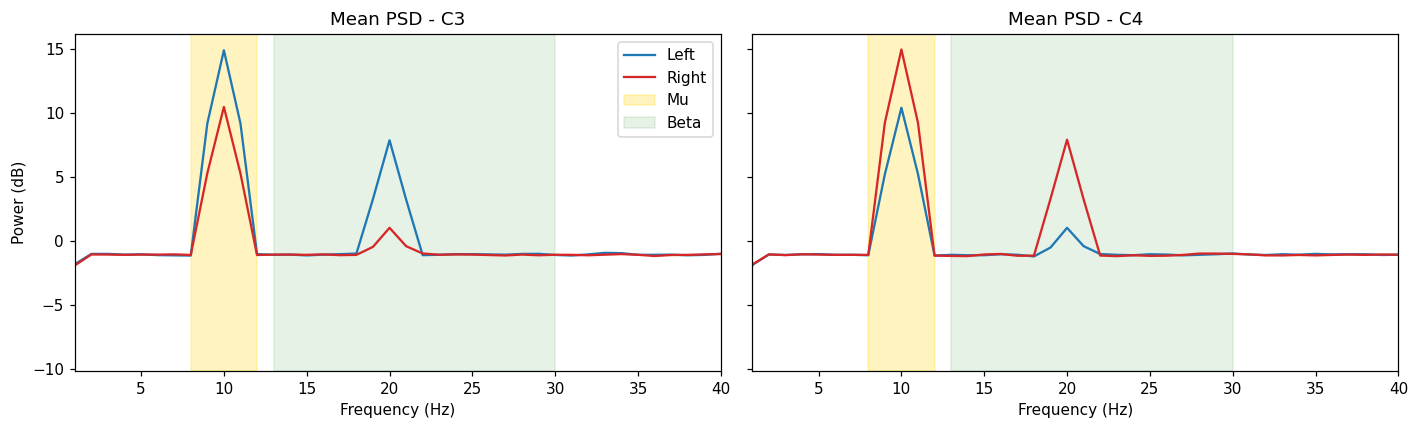

,band,channel,Left,Right,Left vs Right (%)
0,mu,C3,48.078,18.647,157.830
1,mu,C4,18.391,48.715,-62.249
2,beta,C3,21.358,14.037,52.155
3,beta,C4,14.009,21.304,-34.244


In [8]:
ok = [i for i in audit.index[~audit["is_bad"]] if results[i]["psd_c3"] is not None]
labs = audit.loc[ok, "label"].values
psd = {"C3": np.array([results[i]["psd_c3"] for i in ok]), "C4": np.array([results[i]["psd_c4"] for i in ok])}

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, ch in zip(axes, ["C3", "C4"]):
    for cls, col in [("Left", "tab:blue"), ("Right", "tab:red")]:
        ax.plot(freqs, 10 * np.log10(psd[ch][labs == cls].mean(axis=0)), color=col, label=cls)
    ax.axvspan(*MU, color="gold", alpha=0.25, label="Mu"); ax.axvspan(*BETA, color="green", alpha=0.10, label="Beta")
    ax.set_xlim(1, 40); ax.set_xlabel("Frequency (Hz)"); ax.set_title(f"Mean PSD - {ch}")
axes[0].set_ylabel("Power (dB)"); axes[0].legend(); plt.tight_layout(); plt.show()

def band(p, lo, hi):
    m = (freqs >= lo) & (freqs <= hi)
    return trapezoid(p[:, m], freqs[m], axis=1)

rows = []
for bname, (lo, hi) in [("mu", MU), ("beta", BETA)]:
    for ch in ["C3", "C4"]:
        bp = band(psd[ch], lo, hi)
        left, right = bp[labs == "Left"].mean(), bp[labs == "Right"].mean()
        rows.append({"band": bname, "channel": ch, "Left": left, "Right": right, "Left vs Right (%)": 100 * (left - right) / right})
pd.DataFrame(rows).round(3)